                                             CONTENT TYPE PREDICTION MODEL                                                                        

In [1]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score , classification_report

In [2]:
ds = pd.read_csv("Dataset.csv")
ds.tail()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV
8789,s8786,TV Show,YOM,Not Given,Pakistan,6/7/2018,2016,TV-Y7,1 Season,Kids' TV


To check the column of the dataset

In [3]:
print(ds.shape)
print(ds.columns.tolist())

(8790, 10)
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


Understand the target column

type
Movie      6126
TV Show    2664
Name: count, dtype: int64


<Axes: xlabel='type', ylabel='count'>

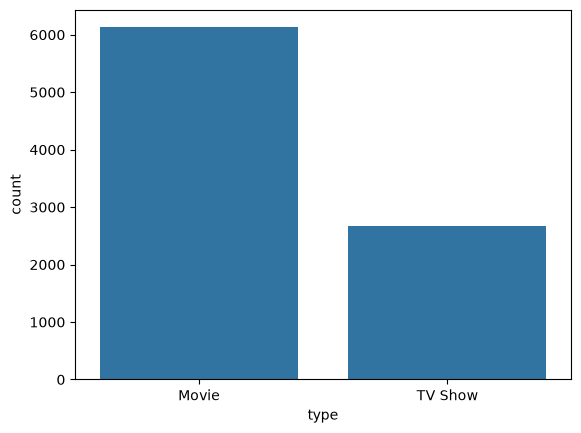

In [4]:
print(ds["type"].value_counts())
sns.countplot(data= ds, x= "type")


SELECT FEATURE

In [5]:
feature = ["director","country","rating","release_year"]
X = ds[feature]
Y = ds['type']
print(X.head())
print(Y.head())

          director        country rating  release_year
0  Kirsten Johnson  United States  PG-13          2020
1  Julien Leclercq         France  TV-MA          2021
2    Mike Flanagan  United States  TV-MA          2021
3    Bruno Garotti         Brazil  TV-PG          2021
4     Haile Gerima  United States  TV-MA          1993
0      Movie
1    TV Show
2    TV Show
3      Movie
4      Movie
Name: type, dtype: object


Making of the training and testing data 

In [6]:
X_train ,X_test, Y_train , Y_test = train_test_split(
    X,
    Y,
    test_size= 0.2,
    random_state= 42,
    stratify= Y
)

print("Training record :" , len(X_train))
print("Testing rocord :" , len(X_test))

Training record : 7032
Testing rocord : 1758


Encoding categorial data 

In [7]:
categorical_feature = ["country", "rating", "director"]

preprocessor = ColumnTransformer(
    transformers= [(
        "encoder", OneHotEncoder (handle_unknown= "ignore"),
        categorical_feature)
    ],
    remainder= "passthrough"
)

Train or create logicstic regression model

In [8]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])
model.fit(X_train, Y_train)
print("Model training completed !")

Model training completed !


c:\Users\suraj\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Make prediction

In [9]:
Y_pred = model.predict(X_test)
print("Prediction")
print(Y_pred[:10])

print("\nAcutal values :")
print(Y_test.head(10).tolist())

Prediction
['Movie' 'Movie' 'Movie' 'Movie' 'TV Show' 'Movie' 'TV Show' 'Movie'
 'Movie' 'Movie']

Acutal values :
['Movie', 'Movie', 'Movie', 'Movie', 'TV Show', 'Movie', 'TV Show', 'Movie', 'Movie', 'Movie']


Check the accuracy of the model

In [10]:
accuracy = accuracy_score(Y_test,Y_pred)
print("Model accuracy: ",round(accuracy*100,2),"%")
print("\n Classification report :")
print(classification_report(Y_test,Y_pred))

Model accuracy:  94.94 %

 Classification report :
              precision    recall  f1-score   support

       Movie       0.96      0.97      0.96      1225
     TV Show       0.93      0.90      0.92       533

    accuracy                           0.95      1758
   macro avg       0.94      0.94      0.94      1758
weighted avg       0.95      0.95      0.95      1758



New Netflix prediction

In [11]:
new_title = pd.DataFrame({
    "director":["Rajkumar Hirani"],
    "country": ["India"],
    "rating": ["PG-13"],
    "release_year":[2023]
})
prediction = model.predict(new_title)
print('Prediciton content type:')
prediction[0]

Prediciton content type:


'Movie'